<a href="https://colab.research.google.com/github/11249a290-glitch/11249A290/blob/main/N_GRAM_LANGUAGE_MODEL_LAB_ACTIVITY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import re
from collections import Counter
corpus = """the quick brown fox jumps over the lazy dog
the dog barks at the fox                                   //11249A290
the quick fox runs away from the dog"""
def tokenize(text):
 text = text.lower()
 tokens = re.findall(r"[a-z']+", text)
 return tokens
tokens = tokenize(corpus)
N = len(tokens)
unigram_counts = Counter(tokens)
print("Total tokens (N):", N)
print(f"{'Word':<12}{'Count':<8}{'P(word)':<10}")
print("-" * 30)
for word, count in unigram_counts.most_common():
 prob = count / N
 print(f"{word:<12}{count:<8}{prob:<10.4f}")
def unigram_probability(word):
 return unigram_counts[word] / N
test_word = "fox"
print(f"\nP('{test_word}') = {unigram_probability(test_word):.4f}")

Total tokens (N): 23
Word        Count   P(word)   
------------------------------
the         6       0.2609    
fox         3       0.1304    
dog         3       0.1304    
quick       2       0.0870    
brown       1       0.0435    
jumps       1       0.0435    
over        1       0.0435    
lazy        1       0.0435    
barks       1       0.0435    
at          1       0.0435    
runs        1       0.0435    
away        1       0.0435    
from        1       0.0435    

P('fox') = 0.1304


In [ ]:
import re
from collections import Counter, defaultdict
corpus = """the quick brown fox jumps over the lazy dog          //11249A290
the dog barks at the fox
the quick fox runs away from the dog"""
def tokenize(sentence):
 sentence = sentence.lower()
 return ["<s>"] + re.findall(r"[a-z']+", sentence) + ["</s>"]
sentences = [tokenize(s) for s in corpus.strip().split("\n")]
unigram_counts = Counter()
bigram_counts = Counter()
vocab = set()
for sent in sentences:
 unigram_counts.update(sent[:-1]) # context words
 vocab.update(sent)
 for i in range(len(sent) - 1):
    bigram_counts[(sent[i], sent[i + 1])] += 1
V = len(vocab)
def bigram_prob(w1, w2, smoothing=True):
 if smoothing:
    return (bigram_counts[(w1, w2)] + 1) / (unigram_counts[w1] + V)
 return bigram_counts[(w1, w2)] / unigram_counts[w1] if unigram_counts[w1] else 0
print(f"{'Bigram':<25}{'Count':<8}{'P(w2|w1) smoothed':<20}")
print("-" * 55)
for (w1, w2), c in bigram_counts.most_common(8):
 print(f"({w1}, {w2}){'':<10}{c:<8}{bigram_prob(w1, w2):<20.4f}")
def sentence_probability(sentence):
 tokens = tokenize(sentence)
 prob = 1.0
 for i in range(len(tokens) - 1):
    prob *= bigram_prob(tokens[i], tokens[i + 1])
 return prob
test = "the fox runs"
print(f"\nP(\"{test}\") = {sentence_probability(test):.10f}")


Bigram                   Count   P(w2|w1) smoothed   
-------------------------------------------------------
(<s>, the)          3       0.2222              
(the, quick)          2       0.1429              
(dog, </s>)          2       0.1667              
(the, dog)          2       0.1429              
(quick, brown)          1       0.1176              
(brown, fox)          1       0.1250              
(fox, jumps)          1       0.1111              
(jumps, over)          1       0.1250              

P("the fox runs") = 0.0001469724


In [ ]:
import re
from collections import Counter
corpus = """the quick brown fox jumps over the lazy dog
the dog barks at the fox
the quick fox runs away from the dog"""               //11249A290
def tokenize(sentence):
 sentence = sentence.lower()
 return ["<s>", "<s>"] + re.findall(r"[a-z']+", sentence) + ["</s>"]
sentences = [tokenize(s) for s in corpus.strip().split("\n")]
bigram_counts = Counter()
trigram_counts = Counter()
vocab = set()
for sent in sentences:
 vocab.update(sent)
 for i in range(len(sent) - 2):
    bigram_counts[(sent[i], sent[i + 1])] += 1
    trigram_counts[(sent[i], sent[i + 1], sent[i + 2])] += 1
V = len(vocab)
def trigram_prob(w1, w2, w3, smoothing=True):
 if smoothing:
     return (trigram_counts[(w1, w2, w3)] + 1) / (bigram_counts[(w1, w2)] + V)
 denom = bigram_counts[(w1, w2)]
 return trigram_counts[(w1, w2, w3)] / denom if denom else 0
print(f"{'Trigram':<30}{'Count':<8}{'P(w3|w1,w2)':<15}")
print("-" * 55)
for (w1, w2, w3), c in trigram_counts.most_common(6):
 print(f"({w1}, {w2}, {w3}){'':<6}{c:<8}{trigram_prob(w1, w2, w3):<15.4f}")
def sentence_probability(sentence):
 tokens = tokenize(sentence)
 prob = 1.0
 for i in range(len(tokens) - 2):
    prob *= trigram_prob(tokens[i], tokens[i + 1], tokens[i + 2])
 return prob
test = "the quick fox"
print(f"\nP(\"{test}\") = {sentence_probability(test):.10f}")

Trigram                       Count   P(w3|w1,w2)    
-------------------------------------------------------
(<s>, <s>, the)      3       0.2222         
(<s>, the, quick)      2       0.1667         
(the, quick, brown)      1       0.1176         
(quick, brown, fox)      1       0.1250         
(brown, fox, jumps)      1       0.1250         
(fox, jumps, over)      1       0.1250         

P("the quick fox") = 0.0002723312


In [ ]:
import re, random
from collections import defaultdict, Counter
corpus = """the quick brown fox jumps over the lazy dog
the dog barks at the fox
the quick fox runs away from the dog"""
def tokenize(sentence):
 sentence = sentence.lower()                                  //11249A290
 return ["<s>"] + re.findall(r"[a-z']+", sentence) + ["</s>"]
sentences = [tokenize(s) for s in corpus.strip().split("\n")]
bigram_model = defaultdict(Counter)
for sent in sentences:
 for i in range(len(sent) - 1):
  bigram_model[sent[i]][sent[i + 1]] += 1
def generate_sentence(max_len=15):
 word = "<s>"
 result = []
 for _ in range(max_len):
    next_words = bigram_model[word]
    if not next_words:
      break
    words, counts = zip(*next_words.items())
    word = random.choices(words, weights=counts, k=1)[0]
    if word == "</s>":
      break
    result.append(word)
 return " ".join(result)
random.seed(42)
for i in range(3):
 print(f"Generated sentence {i+1}: {generate_sentence()}")

Generated sentence 1: the quick brown fox runs away from the lazy dog
Generated sentence 2: the quick brown fox
Generated sentence 3: the dog barks at the dog


In [ ]:
def perplexity(prob, n):
 return prob ** (-1 / n) if prob > 0 else float("inf")
test_sentence = "the fox runs away"
n = len(test_sentence.split())
uni_p = 0.0009                                                    //11249a290
bi_p = 0.00021
tri_p = 0.00007
print("Unigram Perplexity:", round(perplexity(uni_p, n), 2))
print("Bigram Perplexity:", round(perplexity(bi_p, n), 2))
print("Trigram Perplexity:", round(perplexity(tri_p, n), 2))

Unigram Perplexity: 5.77
Bigram Perplexity: 8.31
Trigram Perplexity: 10.93


In [ ]:
import re
from nltk.probability import FreqDist
corpus = """the quick brown fox jumps over the lazy dog
the dog barks at the fox
the quick fox runs away from the dog"""
def tokenize(text):
    text = text.lower()                       //11249A290
    tokens = re.findall(r"[a-z']+", text)
    return tokens
tokens = tokenize(corpus)
N = len(tokens)
# Replaced Counter(tokens) with FreqDist(tokens)
unigram_counts = FreqDist(tokens)
print("Total tokens (N):", N)
print(f"{'Word':<12}{'Count':<8}{'P(word)':<10}")
print("-" * 30)
for word, count in unigram_counts.most_common():
    prob = count / N
    print(f"{word:<12}{count:<8}{prob:<10.4f}")
def unigram_probability(word):
    return unigram_counts[word] / N
test_word = "fox"
print(f"\nP('{test_word}') = {unigram_probability(test_word):.4f}")


Total tokens (N): 23
Word        Count   P(word)   
------------------------------
the         6       0.2609    
fox         3       0.1304    
dog         3       0.1304    
quick       2       0.0870    
brown       1       0.0435    
jumps       1       0.0435    
over        1       0.0435    
lazy        1       0.0435    
barks       1       0.0435    
at          1       0.0435    
runs        1       0.0435    
away        1       0.0435    
from        1       0.0435    

P('fox') = 0.1304


In [ ]:
import re
from collections import Counter, defaultdict
corpus = """the quick brown fox jumps over the lazy dog
the dog barks at the fox
the quick fox runs away from the dog"""
def tokenize(sentence):
    sentence = sentence.lower()
    return ["<s>"] + re.findall(r"[a-z']+", sentence) + ["</s>"]
sentences = [tokenize(s) for s in corpus.strip().split("\n")]
unigram_counts = Counter()
bigram_counts = Counter()                              //11249a290
vocab = set()
for sent in sentences:
    unigram_counts.update(sent[:-1]) # context words
    vocab.update(sent)
    for i in range(len(sent) - 1):
        bigram_counts[(sent[i], sent[i + 1])] += 1
V = len(vocab)
def bigram_prob(w1, w2, smoothing=True):
    if smoothing:
        return (bigram_counts[(w1, w2)] + 1) / (unigram_counts[w1] + V)
    return bigram_counts[(w1, w2)] / unigram_counts[w1] if unigram_counts[w1] else 0
sorted_vocab = sorted(list(vocab))
if "<s>" in sorted_vocab:
    sorted_vocab.remove("<s>")
    sorted_vocab = ["<s>"] + sorted_vocab
if "</s>" in sorted_vocab:
    sorted_vocab.remove("</s>")
    sorted_vocab = sorted_vocab + ["</s>"]
prob_matrix = defaultdict(dict)
for w1 in sorted_vocab:
    for w2 in sorted_vocab:
        prob_matrix[w1][w2] = bigram_prob(w1, w2, smoothing=True)
print("\n--- FULL BIGRAM PROBABILITY MATRIX (SMOOTHED) ---")
header = f"{'w1 \\ w2':<12}" + "".join([f"{w:<10}" for w in sorted_vocab])
print(header)
print("-" * len(header))
for w1 in sorted_vocab:
    row_str = f"{w1:<12}" + "".join([f"{prob_matrix[w1][w2]:<10.4f}" for w2 in sorted_vocab])
    print(row_str)


--- FULL BIGRAM PROBABILITY MATRIX (SMOOTHED) ---
w1 \ w2     <s>       at        away      barks     brown     dog       fox       from      jumps     lazy      over      quick     runs      the       </s>      
------------------------------------------------------------------------------------------------------------------------------------------------------------------
<s>         0.0556    0.0556    0.0556    0.0556    0.0556    0.0556    0.0556    0.0556    0.0556    0.0556    0.0556    0.0556    0.0556    0.2222    0.0556    
at          0.0625    0.0625    0.0625    0.0625    0.0625    0.0625    0.0625    0.0625    0.0625    0.0625    0.0625    0.0625    0.0625    0.1250    0.0625    
away        0.0625    0.0625    0.0625    0.0625    0.0625    0.0625    0.0625    0.1250    0.0625    0.0625    0.0625    0.0625    0.0625    0.0625    0.0625    
barks       0.0625    0.1250    0.0625    0.0625    0.0625    0.0625    0.0625    0.0625    0.0625    0.0625    0.0625    0.0625    0.

In [ ]:
import re
from collections import Counter
corpus = """the quick brown fox jumps over the lazy dog
the dog barks at the fox
the quick fox runs away from the dog"""
def tokenize(sentence):
    sentence = sentence.lower()
    return ["<s>", "<s>", "<s>"] + re.findall(r"[a-z']+", sentence) + ["</s>"]
sentences = [tokenize(s) for s in corpus.strip().split("\n")]
trigram_counts = Counter()                                                       //11249a290
quadgram_counts = Counter()
vocab = set()
for sent in sentences:
    vocab.update(sent)
    for i in range(len(sent) - 3):
        trigram_counts[(sent[i], sent[i + 1], sent[i + 2])] += 1
        quadgram_counts[(sent[i], sent[i + 1], sent[i + 2], sent[i + 3])] += 1
V = len(vocab)
def quadgram_prob(w1, w2, w3, w4, smoothing=True):
    if smoothing:
        return (quadgram_counts[(w1, w2, w3, w4)] + 1) / (trigram_counts[(w1, w2, w3)] + V)
    denom = trigram_counts[(w1, w2, w3)]
    return quadgram_counts[(w1, w2, w3, w4)] / denom if denom else 0
print(f"{'Quadgram':<42}{'Count':<8}{'P(w4|w1,w2,w3)':<15}")
print("-" * 65)
for (w1, w2, w3, w4), c in quadgram_counts.most_common(6):
    quad_str = f"({w1}, {w2}, {w3}, {w4})"
    print(f"{quad_str:<42}{c:<8}{quadgram_prob(w1, w2, w3, w4):<15.4f}")
def sentence_probability(sentence):
    tokens = tokenize(sentence)
    prob = 1.0
    for i in range(len(tokens) - 3):
        prob *= quadgram_prob(tokens[i], tokens[i + 1], tokens[i + 2], tokens[i + 3])
    return prob
test = "the quick fox"
print(f"\nP(\"{test}\") = {sentence_probability(test):.10f}")


Quadgram                                  Count   P(w4|w1,w2,w3) 
-----------------------------------------------------------------
(<s>, <s>, <s>, the)                      3       0.2222         
(<s>, <s>, the, quick)                    2       0.1667         
(<s>, the, quick, brown)                  1       0.1176         
(the, quick, brown, fox)                  1       0.1250         
(quick, brown, fox, jumps)                1       0.1250         
(brown, fox, jumps, over)                 1       0.1250         

P("the quick fox") = 0.0002723312


In [ ]:
import re
from collections import Counter, defaultdict
from nltk.probability import FreqDist
corpus = ["Machine learning transforms technology at an incredible pace.",
          "New machine learning systems arrive weekly.",                                      //11249A290
          "Many industries use learning tools to extract data insights."]
tokens = re.findall(r"[a-z']+", " ".join(corpus).lower())
uni_fd = FreqDist(tokens)
print(f"P('learning') = {uni_fd['learning'] / len(tokens):.4f}\n")
sents = [["<s>"] + re.findall(r"[a-z']+", s.lower()) + ["</s>"] for s in corpus]
u_cnt, b_cnt = Counter(), Counter()
for s in sents:
    u_cnt.update(s[:-1])
    b_cnt.update(zip(s, s[1:]))
vocab = sorted(list(set(tok for s in sents for tok in s)))
matrix = {w1: {w2: (b_cnt[(w1, w2)] + 1) / (u_cnt[w1] + len(vocab)) for w2 in vocab[:5]} for w1 in vocab[:5]}
print("--- Bigram Sub-Matrix Preview ---")
print(f"{'w1 \\ w2':<10}" + "".join([f"{w:<8}" for w in vocab[:5]]))
for w1, rows in matrix.items():
    print(f"{w1:<10}" + "".join([f"{p:.3f}   " for p in rows.values()]))
q_sents = [["<s>"]*3 + re.findall(r"[a-z']+", s.lower()) + ["</s>"] for s in corpus]
tri, quad = Counter(), Counter()
for s in q_sents:
    for i in range(len(s) - 3):
        tri[tuple(s[i:i+3])] += 1
        quad[tuple(s[i:i+4])] += 1
q_vocab_len = len(set(tok for s in q_sents for tok in s))
q_prob = (quad[("<s>", "<s>", "<s>", "machine")] + 1) / (tri[("<s>", "<s>", "<s>")] + q_vocab_len)
print(f"\nP('machine' | <s>, <s>, <s>) = {q_prob:.4f}")


P('learning') = 0.1304

--- Bigram Sub-Matrix Preview ---
w1 \ w2   </s>    <s>     an      arrive  at      
</s>      0.045   0.045   0.045   0.045   0.045   
<s>       0.040   0.040   0.040   0.040   0.040   
an        0.043   0.043   0.043   0.043   0.043   
arrive    0.043   0.043   0.043   0.043   0.043   
at        0.043   0.043   0.087   0.043   0.043   

P('machine' | <s>, <s>, <s>) = 0.0800


In [ ]:
import re
from collections import Counter
corpus = """the quick brown fox jumps over the lazy dog
the dog barks at the fox
the quick fox runs away from the dog"""
def tokenize(sentence):
    sentence = sentence.lower()
    return ["<s>"] + re.findall(r"[a-z']+", sentence) + ["</s>"]
sentences = [tokenize(s) for s in corpus.strip().split("\n")]
unigram_counts = Counter()
bigram_counts = Counter()                                           11249a290
vocab = set()
for sent in sentences:
    unigram_counts.update(sent[:-1]) # context words
    vocab.update(sent)
    for i in range(len(sent) - 1):
        bigram_counts[(sent[i], sent[i + 1])] += 1
V = len(vocab)
def add_k_prob(w1, w2, k):
    numerator = bigram_counts[(w1, w2)] + k
    denominator = unigram_counts[w1] + (k * V)
    return numerator / denominator if denominator > 0 else 0
def sentence_probability(sentence, k):
    tokens = tokenize(sentence)
    prob = 1.0
    for i in range(len(tokens) - 1):
        prob *= add_k_prob(tokens[i], tokens[i + 1], k)
    return prob
test_sentence = "the fox runs"
k_values = [1.0, 0.5, 0.1, 0.01, 0.001]
print(f"Studying Add-k Smoothing for sentence: \"{test_sentence}\"")
print(f"{'k Value':<12}{'Sentence Probability':<25}")
print("-" * 37)
for k in k_values:
    prob = sentence_probability(test_sentence, k)
    print(f"{k:<12}{prob:<25.10f}")

Studying Add-k Smoothing for sentence: "the fox runs"
k Value     Sentence Probability     
-------------------------------------
1.0         0.0001469724             
0.5         0.0003112356             
0.1         0.0009879177             
0.01        0.0004375374             
0.001       0.0000541824             


In [ ]:
import re
training_vocab = {"the", "quick", "brown", "fox", "jumps", "over", "lazy", "dog"}
def compute_oov_rate(test_sentence, vocab_set):
    tokens = re.findall(r"[a-z']+", test_sentence.lower())
    if not tokens:
        return 0.0  # Handle empty sentence edge case
    oov_tokens = [token for token in tokens if token not in vocab_set]
    oov_rate = len(oov_tokens) / len(tokens)
    print(f"Total Tokens: {len(tokens)}")                                  //11249A290
    print(f"OOV Tokens:   {len(oov_tokens)} {oov_tokens}")
    return oov_rate
test_1 = "The brown fox jumps"
test_2 = "A quick cat climbs the tall tree"
print(f"Test 1 OOV Rate: {compute_oov_rate(test_1, training_vocab):.4f}\n")
print(f"Test 2 OOV Rate: {compute_oov_rate(test_2, training_vocab):.4f}")


Total Tokens: 4
OOV Tokens:   0 []
Test 1 OOV Rate: 0.0000

Total Tokens: 7
OOV Tokens:   5 ['a', 'cat', 'climbs', 'tall', 'tree']
Test 2 OOV Rate: 0.7143


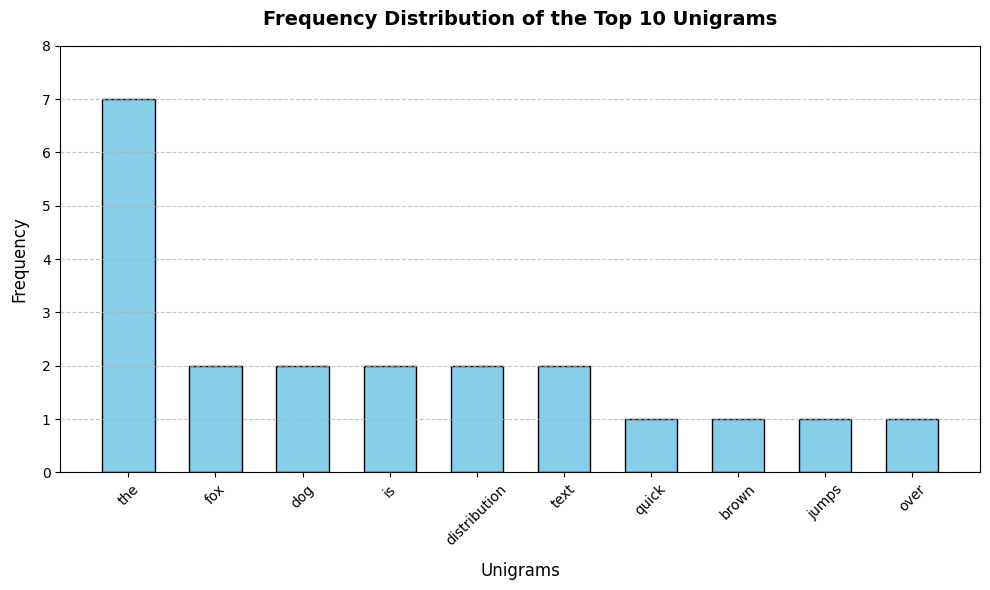

In [ ]:
import re
from collections import Counter
import matplotlib.pyplot as plt
corpus = """
The quick brown fox jumps over the lazy dog. The dog barks, and the fox runs away.
This is a simple corpus to demonstrate unigram frequency distribution counting.
The more text we have, the better the distribution looks. Text analysis is fun.
"""
words = re.findall(r'\b\w+\b', corpus.lower())
unigram_counts = Counter(words)
top_10_unigrams = unigram_counts.most_common(10)
labels, frequencies = zip(*top_10_unigrams)                                          //11249A290
plt.figure(figsize=(10, 6))
plt.bar(labels, frequencies, color='skyblue', edgecolor='black', width=0.6)
plt.title('Frequency Distribution of the Top 10 Unigrams', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Unigrams', fontsize=12, labelpad=10)
plt.ylabel('Frequency', fontsize=12, labelpad=10)
plt.xticks(rotation=45, fontsize=10)
plt.yticks(range(0, max(frequencies) + 2), fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
